In [ ]:
import torch
from torch import nn, Tensor

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import numpy as np

# Flow Matching Exercises and Solutions

## Exercise 1: Understanding Flow Matching Theory
**Question:** What is flow matching and how does the velocity field define the transformation from noise to data? Explain the intuition behind the method.

## Exercise 2: Network Architecture Implementation

**Task:** Complete the Flow class implementation with appropriate architecture for the velocity field.

In [ ]:
class Flow(nn.Module):
    def __init__(self, ...):
        super().__init__()

## Exercise 3: Training Implementation

**Task:** Implement training loop with flow matching objective.

In [ ]:
# Training setup
flow = Flow()
optimizer = torch.optim.Adam(flow.parameters(), 1e-2)
loss_fn = ...

# Training loop
for _ in range(10000):
    # Generate data from moons dataset
    x_1 = Tensor(make_moons(256, noise=0.05)[0])
    ...
    optimizer.step()

## Exercise 4: Sampling with Euler Integration

**Task:** Implement a sampling function using Euler integration with the learned velocity field.

In [ ]:
def sample_euler(flow, num_steps=100, batch_size=64, device='cpu'):
    """Sample from the flow model using Euler integration."""
    ...
    return x

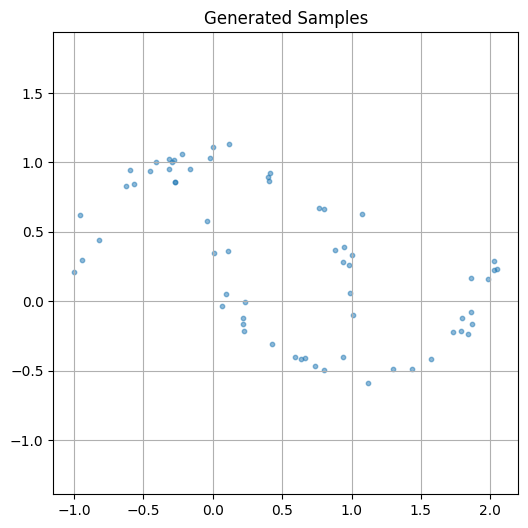

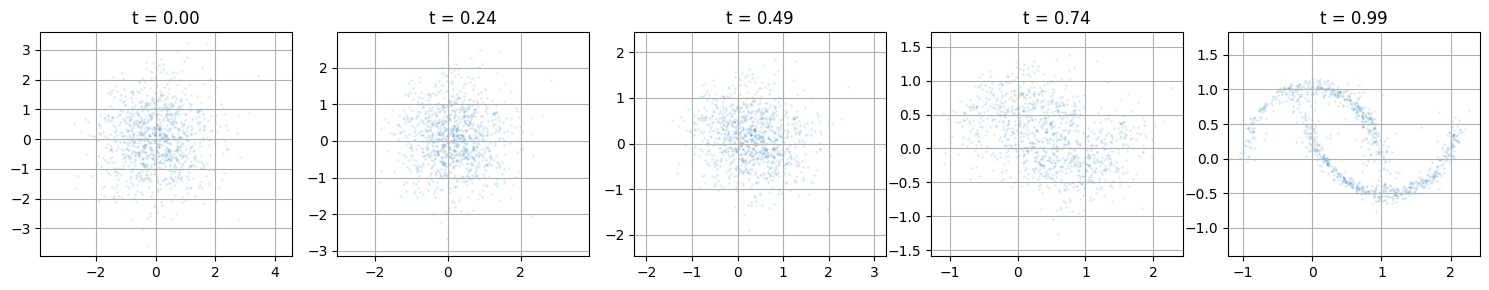

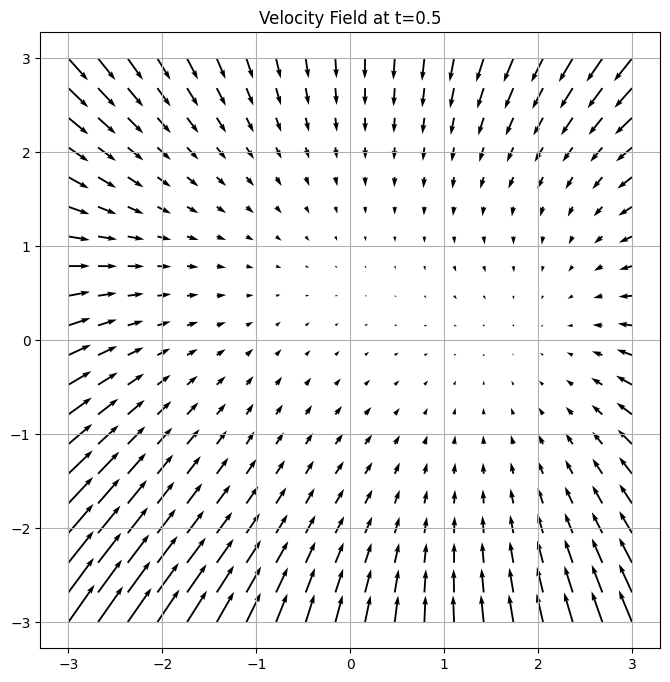

In [ ]:
def plot_samples(samples, title="Samples", show_density=False):
    """Plot 2D samples with optional density estimation"""
    plt.figure(figsize=(6, 6))

    # Convert samples to numpy if they're tensors
    if torch.is_tensor(samples):
        samples = samples.detach().cpu().numpy()

    # Plot individual points
    plt.scatter(samples[:, 0], samples[:, 1], s=10, alpha=0.5)

    if show_density:
        # Add kernel density estimate
        from scipy.stats import gaussian_kde
        kde = gaussian_kde(samples.T)
        xmin, xmax = samples[:, 0].min(), samples[:, 0].max()
        ymin, ymax = samples[:, 1].min(), samples[:, 1].max()
        X, Y = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
        positions = np.vstack([X.ravel(), Y.ravel()])
        Z = np.reshape(kde(positions).T, X.shape)
        plt.contour(X, Y, Z, levels=10, alpha=0.3, cmap='viridis')

    plt.title(title)
    plt.axis('equal')
    plt.grid(True)
    plt.show()